# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr
from scipy.stats import chi2_contingency


### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv("/datasets/novaretail_comportamiento_clientes_2024.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna edad requiere un cambio de formato, ya que esta solo se puede medir con números enteros .


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Corregir el tipo de dato
df["edad"] = df["edad"].astype("int64")

In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- `edad` en esta variable podemos observar que la mayoría de los datos se concentra en 46 años
- `nivel_ingreso` podemos obeservar que el nivel de ingreso promedio es de 30,019.70
- `gasto_publicidad_dirigida` el gasto en publicidad promedio es de 20.15
- `satisfaccion` se concentra en su mayoría en un nivel 4 
- `ingreso_anual` el ingreso anual promedio es de 36.594

#### Explorar variables binarias

In [7]:
# Verificar que cada columna tenga únicamente dos valores posibles
print('Valores únicos en miembro_premium:', df["miembro_premium"].unique())
print("Conteo de valores:\n", df["miembro_premium"].value_counts())
print("-"*40)
print("Valores únicos en abandono:", df["abandono"].unique())
print("Conteo de valores:\n", df["abandono"].value_counts())

Valores únicos en miembro_premium: [0 1]
Conteo de valores:
 0    12911
1     2089
Name: miembro_premium, dtype: int64
----------------------------------------
Valores únicos en abandono: [0 1]
Conteo de valores:
 0    12739
1     2261
Name: abandono, dtype: int64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium` hay un mayor número de miembros que no cuentan con una suscripción premium.
- `abandono` se tiene una mayor presencia de usuarios que se mantienen en la plataforma.

#### Explorar variables categóricas

In [8]:
# Verificar el número de valores únicos por variable categórica
df[["id_cliente", "tipo_dispositivo", "region"]].nunique()

id_cliente          15000
tipo_dispositivo        3
region                  4
dtype: int64

In [9]:
# Explorar variables categóricas y cómo se distribuyen
print("--- Distribución de tipo_dispositivo ---")
print(df["tipo_dispositivo"].value_counts(normalize=True) * 100)

print("\n--- Distribución de region ---")
print(df["region"].value_counts(normalize=True) * 100)

--- Distribución de tipo_dispositivo ---
móvil         65.453333
escritorio    24.800000
tablet         9.746667
Name: tipo_dispositivo, dtype: float64

--- Distribución de region ---
norte    29.30
oeste    25.40
sur      24.84
este     20.46
Name: region, dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` se tiene una mayor presencia de móviles y escritorio.
- `region` las regiones norte y oeste son quienes tienen una mayor presencia en los datos.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

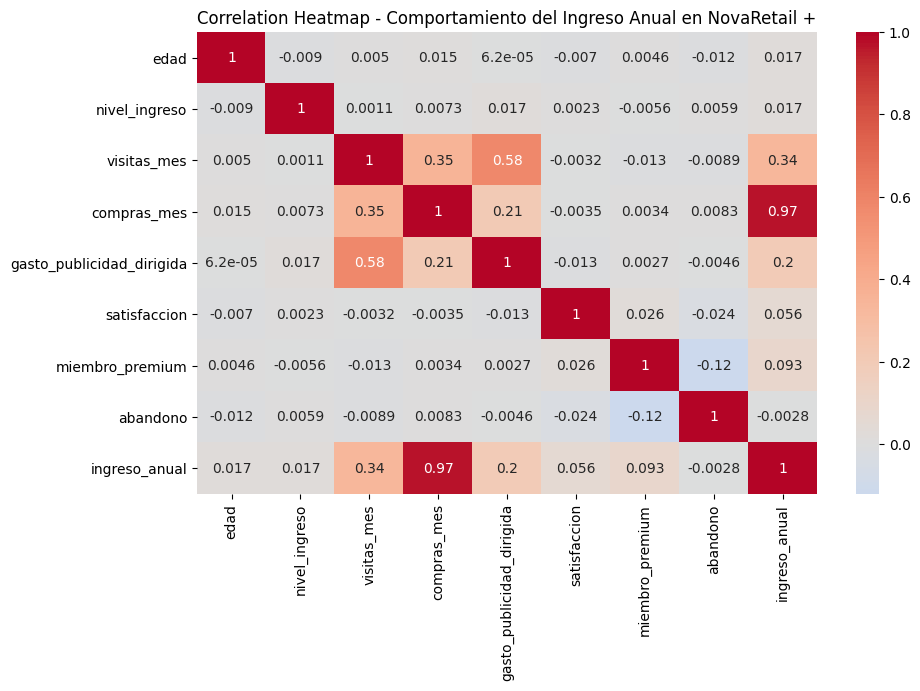

In [10]:
# Visualizar la matriz de correlación para identificar relaciones
corr = df.corr()
corr
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap - Comportamiento del Ingreso Anual en NovaRetail +")
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
- Se observa que tenemos una fuerte correlación entre gasto_publicidad_dirigida y visitas_mes, siendo esto algo esperado ya que una mayor publicidad atrae usuarios. Posteriormente tenemos compras_mes y visitas_mes donde se tiene una correlación moderada, misma que también es esperada ya que si se tiene un mayor nivel de visitas se tiene un mayor nivel de compras, al igual que nos indica que hay un buen comportamiento en los usuarios.



Observaciones respecto a `ingreso_anual`  
- Presenta que la mayor correlación que se tiene es con visitas_mes y una correlación moderada con gasto_publicidad_dirigida.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

### Scatterplot para pares clave

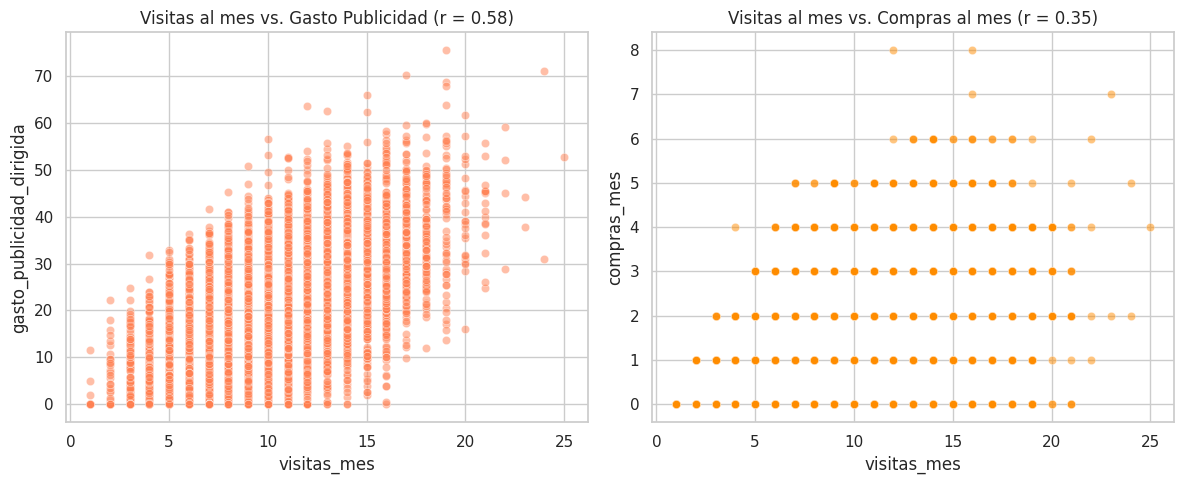

In [11]:
# Visualizar pares de variables con relaciones moderadas o fuertes
# Configuración del estilo
sns.set_theme(style="whitegrid")

# Crear una figura con los 2 pares de variables restantes
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. visitas_mes vs gasto_publicidad_dirigida (r = 0.58)
sns.scatterplot(
    data=df,
    x="visitas_mes",
    y="gasto_publicidad_dirigida",
    ax=axes[0],
    color="coral",
    alpha=0.5,
)
axes[0].set_title("Visitas al mes vs. Gasto Publicidad (r = 0.58)")

# 2. visitas_mes vs compras_mes (r = 0.35)
sns.scatterplot(
    data=df,
    x="visitas_mes",
    y="compras_mes",
    ax=axes[1],
    color="darkorange",
    alpha=0.5,
)
axes[1].set_title("Visitas al mes vs. Compras al mes (r = 0.35)")

plt.tight_layout()
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)


**`visitas_mes` vs `gasto_publicidad_dirigida`**
- **Dirección:** Positiva moderada-alta teniendo (r = 0.58).
- **Dispersión:** Media debido a que existe una clara tendencia ascendente, aunque con variabilidad moderada alrededor de la línea.
- **Posible colinealidad:** Moderada.

**`visitas_mes` vs `compras_mes`**

- **Dirección:** Positiva moderada ya que tenemos (r = 0.35).
- **Dispersión:** Alta-media pues los puntos muestran dispersión considerable, aunque se percibe una inclinación ascendente.
- **Presencia de outliers:** Probable presencia de outliers ya que los visitantes frecuentes que no compran o compradores con pocas visitas.
- **Posible colinealidad:** Baja.


## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [12]:
# Calcular correlación entre variables relevantes
df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='pearson')

0.5789472719412827

In [13]:
# Calcular correlación entre variables relevantes
df['visitas_mes'].corr(df['compras_mes'], method='spearman')

0.33294292722789276

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

**gasto_publicidad_dirigida vs visitas_mes**
- Correlación moderada positiva ya que nos dio como resultado 0.578
- Existe una posibilidad de una colinealidad media, ya que el gasto publicitario está positivamente asociado con el tráfico de visitas.

**visitas_mes vs compras_mes**
- Correlación débil positiva, teniendo en cuenta se obtuvi 0.332
- La posibilidad de una colinealidad es baja, ya que muestra que a mayor número de visitas hay una tendencia a realizar más compras, aunque no de forma estrictamente proporcional. 

### Punto-biserial

In [17]:
# Función para calcular el punto-biseral
pointbiserialr(df["miembro_premium"], df["ingreso_anual"])

SignificanceResult(statistic=0.0930994396198015, pvalue=3.0943076155242597e-30)

In [19]:
pointbiserialr(df["miembro_premium"], df["abandono"])

SignificanceResult(statistic=-0.1204878339871541, pvalue=1.2730798507359719e-49)

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**var1 vs var2**
- Relación débil entre miembro premium y el ingreso anual, no aportan lo suficiente a diferencia de los usuarios que no cuentan con este dsitintivo. 

**var2 vs var3**
- Relación débil e indica que los miembros premium tienen una probabilidad menor de abandonar la plataforma a diferencia de los usuarios que no lo son.

### V de Cramér

In [ ]:
# Función para calcular V de Cramér
tabla = pd.crosstab(df["tipo_dispositivo"], df["region"])
tabla

In [ ]:
# Aplicar V de Cramér en variables relevantes
chi2, p, dof, expected = chi2_contingency(tabla)
chi2
n = tabla.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(tabla.shape) -1)))
cramers_v


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

Observaciones V de Cramér
Se tiene una relación muy débil entre la región y el tipo de dispositivo, por lo que si se requiere tomar alguna decisión sobre esta relación. 


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**: Completa los siguientes bloques.   
Si lo crees necesario, puedes agregar mas hallazgos.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### Hallazgo 1 Gasto en publicidad vs visitas mensuales 

**Evidencia visual:**   
scatterplot y heatmap

**Evidencia numérica:** 
Pearson = 0.58

**Interpretación**  
Como pudimos observar en el scatterplot se tiene una tendencia ascendente, aunque con una colinealidad moderada.

**No podemos afirmar**  
No podemos afirmar que un mayor gasto en publicidad está directamente relacionado con las visitas al mes. 

**Implicación de negocio**  
Podríamos implementar un experimento el cual se pueda medir el impacto entre notificaciones por la app o en el sitio web, con notificaciones del correo electrónico vs publicidad.

### Hallazgo 2 Miembros premium vs abandono 

**Evidencia visual:**   
**Evidencia numérica:** 
Punto-biserial -0.12 (negativa, relación débil)
**Interpretación**  
Existe una relación inversa que nos indica que el abandono disminuye siempre y cuando los miembros premium aumemten.

**No podemos afirmar**  
Que esto sea una relación causal, es decir que la membresía premium retenga a los clientes.

**Implicación de negocio**  
No debe utilizarse como criterio único de segmentación, conviene analizar junto con otras métricas.

## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**: Completa el siguiente bloque.   
Modifica según creas necesario.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### **Limitaciones**
- El análisis indica Correlación no causalidad
- Posibles efectos de segmentación no explorados

### **Próximos pasos** 

Probar segmentación adicional
- Análisis por cohortes.
- Segmentación por dispositivo y región.

